In [1]:
import sim_function
from pathlib import Path

import numpy as np
from scipy import stats 
import matplotlib.pyplot as plt

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


In [2]:
para = {
    'nubar': 0.9,
    'theta': 0.1,
    'delta': 0, 
    'boundary': 10000,
    'ngen': 128,
    'ninit': 1
}

delta_values = [0, 0.02, 0.05, 0.08]

nrep = 10000

In [3]:
def run_simulation(para):
  
  final_sizes = np.full(nrep, np.nan)
  
  for j in range(nrep):
    out = sim_function.sim(para)
    final_sizes[j] = out['final_size']
    if j % 2000 == 0:
      print(f"Simulation {j}/{nrep} completed")
  
  cdf = stats.ecdf(final_sizes).cdf
  quants = cdf.quantiles
  probs = 1 - cdf.probabilities
  
  floor = probs[probs > 0].min()
  probs[probs == 0] = floor
  
  return quants, probs

In [4]:
def run_batch(para, delta_values):
  quants_list = []
  probs_list = []
  
  for delta in delta_values:
    this_para = para.copy()
    this_para['delta'] = delta
    quants, probs = run_simulation(this_para)
    quants_list.append(quants)
    probs_list.append(probs)
  
  return quants_list, probs_list

Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 completed
Simulation 4000/10000 completed
Simulation 6000/10000 completed
Simulation 8000/10000 completed
Simulation 0/10000 completed
Simulation 2000/10000 complet

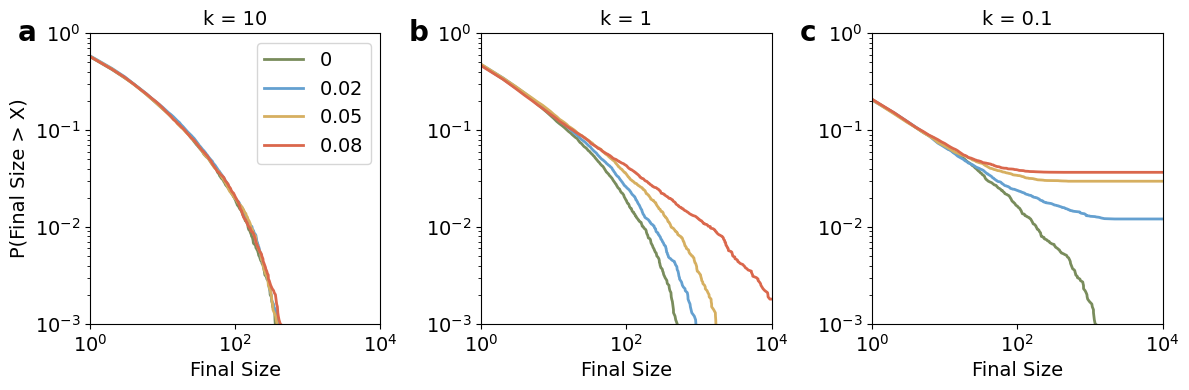

In [5]:
colors = ['#798C5C', '#64A0D0', '#D6AF60', '#DA674C']

x_min, x_max = 1, 10000
y_min, y_max = 0.001, 1

fontsize = 14
labels = ['a', 'b', 'c']

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

thetas = [10, 1, 0.1]
for idx, (ax, theta) in enumerate(zip(axes, thetas)):
    para['theta'] = theta
    q, p = run_batch(para, delta_values)

    for i, delta in enumerate(delta_values):
        ax.plot(q[i], p[i],
                label=fr'${delta}$', 
                color=colors[i], 
                linewidth=2)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Final Size', fontsize=fontsize)
    ax.set_ylabel('P(Final Size > X)', fontsize=fontsize)
    ax.set_title(f'k = {theta}', fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    
    # panel label
    ax.text(-0.25, 1.05, labels[idx],
            transform=ax.transAxes,
            fontsize=20,
            fontweight='bold',
            va='top', ha='left')
    
    if ax != axes[0]:
        ax.set_ylabel('')

axes[0].legend(fontsize=fontsize)
plt.tight_layout()
fig.savefig(figures_dir / "final_size_cdf.pdf", format="pdf")
plt.show()
